# Lab 05: PCA and autoencoders for Earth observation

1. **PCA:** reduce patches of different land cover types to three dimensions and check whether they form clusters.
2. **Super-resolution:** use a convolutional autoencoder to enhance the resolution of a Sentinel-2 image.

**Data:** Sentinel-2 L2A, bands B02, B03, B04 and B08 (10 m), 16-bit TIFF files from the Copernicus Browser. Forest and urban patches come from the six locations used in Lab 04 (23.10.2026). Water patches come from the reservoir in the lake Śniardwy in northeastern Poland (03.10.2026).

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install rasterio -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import tensorflow as tf
from pathlib import Path

Mounted at /content/drive


In [23]:
LAB4_DATA = Path("/content/drive/MyDrive/ml_lab4_data")    # forest_* and urban_* folders
WATER_IMAGE = Path("/content/drive/MyDrive/ml_lab2_data/water")    # Lab 02 image with the reservoir
# rectangles containing only water: (row_start, row_end, col_start, col_end)
WATER_AREAS = [(100, 250, 200, 350)]

BANDS = ["B02", "B03", "B04", "B08"]
SEED = 42
rng = np.random.default_rng(SEED)

forest_lubliniec     shape: (986, 1089, 4)
forest_niepolomice   shape: (745, 877, 4)
forest_opole         shape: (1326, 1246, 4)
urban_katowice       shape: (621, 994, 4)
urban_krakow         shape: (608, 954, 4)
urban_warsaw         shape: (1001, 1001, 4)


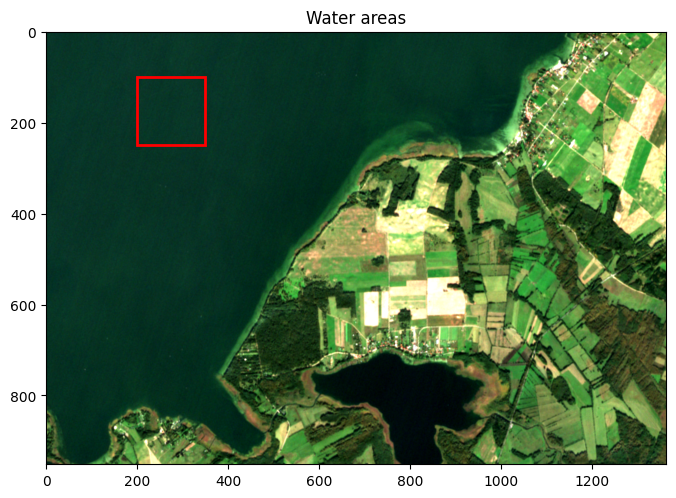

In [24]:
def load_image(folder):
    # Loads the four bands of one image into an array of shape (rows, cols, bands).
    layers = []
    for b in BANDS:
        files = [p for p in folder.iterdir() if b in p.name.upper()]
        if len(files) != 1:
            raise FileNotFoundError(f"{folder}: expected 1 file for {b}, found {len(files)}")
        with rasterio.open(files[0]) as src:
            layers.append(src.read(1).astype(np.float32))
    return np.stack(layers, axis=-1)

def to_rgb(img, lo=None, hi=None):
    # True color composite (B04, B03, B02) with a contrast stretch, for display only.
    rgb = img[..., [2, 1, 0]]
    if lo is None:
        lo, hi = np.percentile(rgb[rgb > 0], [2, 98])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

locations = {f.name: load_image(f) for f in sorted(LAB4_DATA.iterdir())
             if f.is_dir() and f.name.split("_")[0] in ("forest", "urban")}
for name, img in locations.items():
    print(f"{name:20} shape: {img.shape}")

water_img = load_image(WATER_IMAGE) if WATER_AREAS else None
if water_img is not None:
    import matplotlib.patches as patches
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(to_rgb(water_img))
    for r0, r1, c0, c1 in WATER_AREAS:
        ax.add_patch(patches.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='red', linewidth=2))
    ax.set_title("Water areas")
    plt.show()

# Part 1: PCA of land cover patches

**Principal Component Analysis (PCA)** finds the directions in the data along which the data vary the most. Each patch of 16 * 16 pixels with 4 bands is described by 1024 numbers, i.e. it is a point in a 1024-dimensional space, which cannot be visualised. PCA rotates this space so that the first new axis (the first principal component, PC1) points in the direction of the largest variance, PC2 in the direction of the largest remaining variance, and so on. Keeping only the first three components projects every patch onto a point in 3D, losing as little information as possible.

PCA is closely related to the SVD from Lab 01: the principal components are the right singular vectors of the (centred) data matrix, and the squared singular values tell how much variance each component explains. It is therefore implemented here from scratch with np.linalg.svd.

PCA is unsupervised: it does not use the land cover labels. The labels are only used afterwards to colour the points and check whether patches of the same type end up close to each other.

In [25]:
PCA_PATCH = 16      # patch size (16 x 16 px = 160 x 160 m)
PCA_MAX = 300       # patches per location

def extract_patches(img, size, stride):
    # Cuts the image into size x size patches; drops patches with no-data pixels (0 in all bands).
    H, W, _ = img.shape
    p = np.array([img[r:r + size, c:c + size]
                  for r in range(0, H - size + 1, stride)
                  for c in range(0, W - size + 1, stride)])
    return p[~(p == 0).all(axis=-1).any(axis=(1, 2))]

def sample(p, n):
    return p[rng.choice(len(p), n, replace=False)] if len(p) > n else p

patch_list, label_list = [], []
for name, img in locations.items():
    p = sample(extract_patches(img, PCA_PATCH, PCA_PATCH), PCA_MAX)
    patch_list.append(p)
    label_list += [name.split("_")[0]] * len(p)

if water_img is not None:
    water = np.concatenate([extract_patches(water_img[r0:r1, c0:c1], PCA_PATCH, PCA_PATCH // 2)
                            for r0, r1, c0, c1 in WATER_AREAS])
    water = sample(water, PCA_MAX)
    patch_list.append(water)
    label_list += ["water"] * len(water)

P = np.concatenate(patch_list)
labels = np.array(label_list)
print("Patches:", P.shape)
print(pd.Series(labels).value_counts().to_string())

Patches: (2089, 16, 16, 4)
forest    900
urban     900
water     289


Variance explained by the first components:
  PC1:  40.9%   (cumulative  40.9%)
  PC2:  18.2%   (cumulative  59.1%)
  PC3:   5.7%   (cumulative  64.8%)
  PC4:   4.9%   (cumulative  69.7%)
  PC5:   2.8%   (cumulative  72.5%)


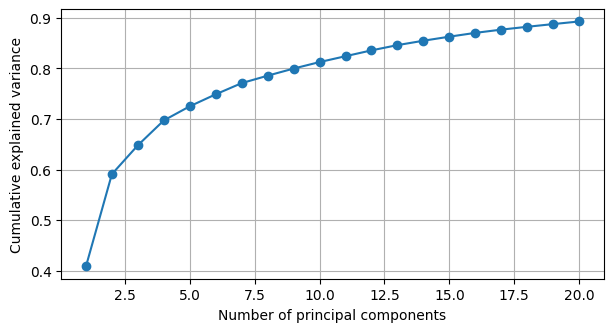

In [26]:
# data matrix: one row per patch, 16*16*4 = 1024 columns
X = P.reshape(len(P), -1)

# standardize every column, so that bright bands (B08) do not dominate the variance
X_mean, X_std = X.mean(axis=0), X.std(axis=0)
Xs = (X - X_mean) / X_std

# PCA from scratch with SVD
U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
explained = S**2 / np.sum(S**2)       # share of variance explained by each component
scores = Xs @ Vt[:3].T                 # coordinates of every patch in PC1, PC2, PC3

print("Variance explained by the first components:")
for i in range(5):
    print(f"  PC{i + 1}: {explained[i]:6.1%}   (cumulative {explained[:i + 1].sum():6.1%})")

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, 21), np.cumsum(explained[:20]), marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.grid(True)
plt.show()

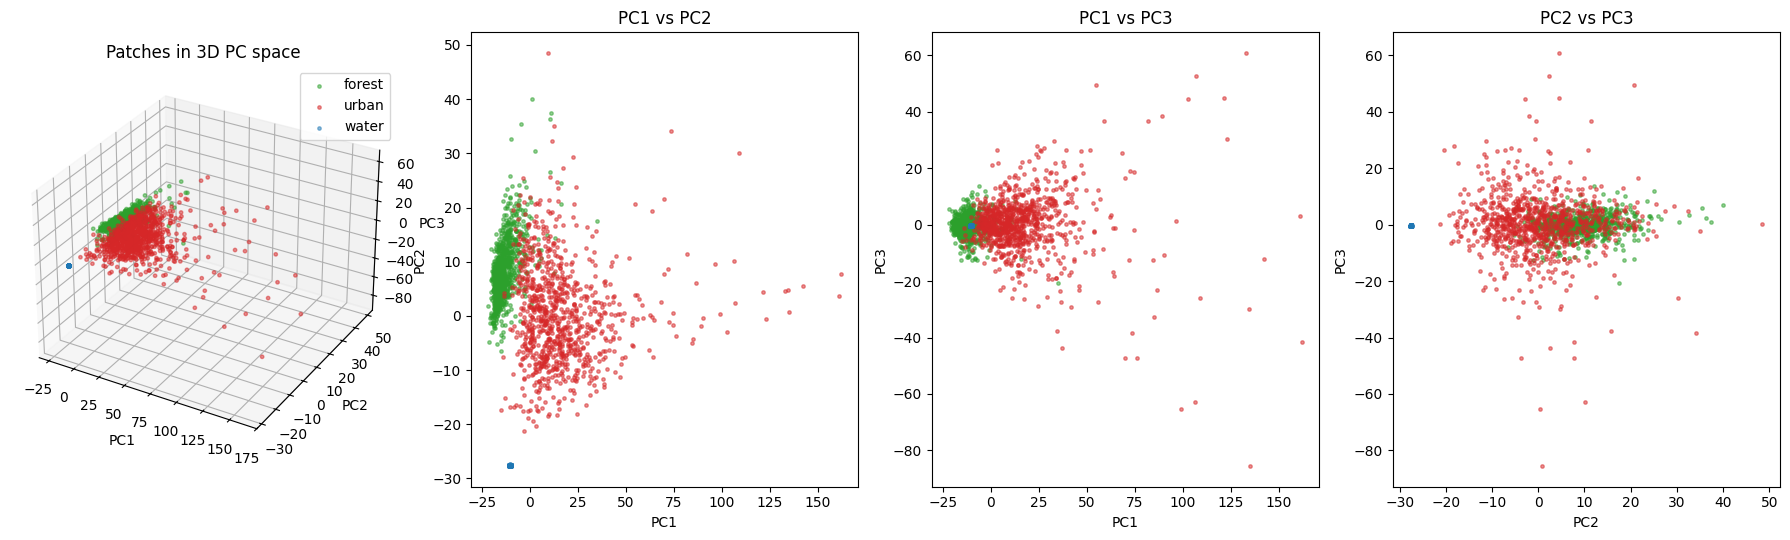

In [27]:
COLORS = {"forest": "tab:green", "urban": "tab:red", "water": "tab:blue"}

fig = plt.figure(figsize=(18, 5.5))
ax = fig.add_subplot(1, 4, 1, projection='3d')
for cls, col in COLORS.items():
    m = labels == cls
    if m.any():
        ax.scatter(scores[m, 0], scores[m, 1], scores[m, 2], s=6, alpha=0.5, c=col, label=cls)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Patches in 3D PC space")
ax.legend()

for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)], start=2):
    ax = fig.add_subplot(1, 4, k)
    for cls, col in COLORS.items():
        m = labels == cls
        if m.any():
            ax.scatter(scores[m, i], scores[m, j], s=6, alpha=0.5, c=col, label=cls)
    ax.set_xlabel(f"PC{i + 1}"); ax.set_ylabel(f"PC{j + 1}")
    ax.set_title(f"PC{i + 1} vs PC{j + 1}")
plt.tight_layout()
plt.show()

Class             centre (PC1, PC2, PC3)  mean std
forest               [-13.2   8.6  -0.2]       4.8
urban                   [16.5  0.3  0.3]      13.9
water                [-10.3 -27.6  -0.4]       0.1


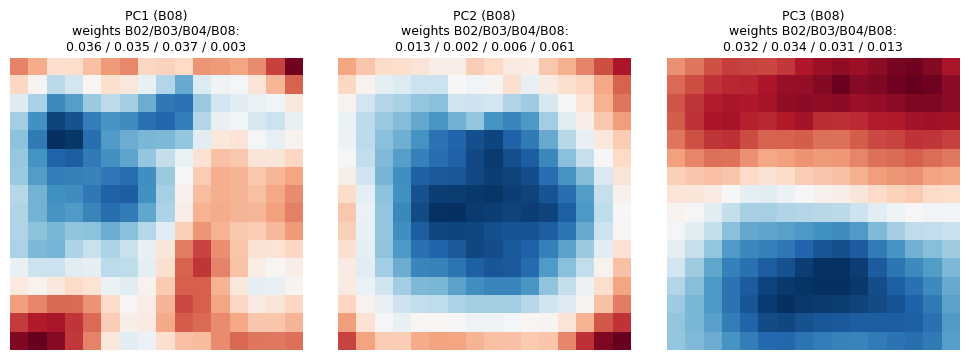

In [28]:
# separation check: distance between class centres in PC space relative to the spread of the classes
centres = {cls: scores[labels == cls].mean(axis=0) for cls in COLORS if (labels == cls).any()}
spread = {cls: scores[labels == cls].std(axis=0).mean() for cls in centres}
print(f"{'Class':8}{'centre (PC1, PC2, PC3)':>32}{'mean std':>10}")
for cls in centres:
    print(f"{cls:8}{np.array2string(centres[cls], precision=1):>32}{spread[cls]:>10.1f}")

# extra: what do the principal components look like? (B08 channel of the first 3 components)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for i, ax in enumerate(axes):
    comp = Vt[i].reshape(PCA_PATCH, PCA_PATCH, len(BANDS))
    ax.imshow(comp[..., 3], cmap='RdBu')
    band_weights = np.abs(comp).mean(axis=(0, 1))
    ax.set_title(f"PC{i + 1} (B08)\nweights B02/B03/B04/B08:\n" +
                 " / ".join(f"{w:.3f}" for w in band_weights), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Observations – PCA

The first three principal components explain 64.8% of the variance of the 1,024-dimensional patch data (PC1: 40.9%, PC2: 18.2%, PC3: 5.7%). The first two components alone explain 59.1%, while the remaining variance is spread over many components, each explaining only a few percent, which most likely corresponds to fine spatial details and noise within the patches.

The land cover types clearly form separate clusters in the PC space, even though PCA did not use the labels at all. The separation is visible mainly in the PC1–PC2 plane:

- PC1 is dominated by the visible bands (weights about 0.036 for B02, B03 and B04, but only 0.003 for B08), so it describes the overall brightness of the patch in visible light. Urban patches have the highest values, as roofs, concrete and asphalt are bright, while forest and water are dark.
- PC2 is dominated by the near-infrared band B08 (weight 0.061), so it separates vegetation from water: forest has high PC2 values, as vegetation strongly reflects near-infrared light, while water has very low values, as it absorbs it.
- PC3 shows a gradient between the upper and lower part of the patch, so it describes spatial structure (e.g. edges) rather than spectral properties. All three classes are centred around zero in PC3, so this component does not help to separate them.

The clusters differ strongly in their spread. Water forms an extremely compact cluster (mean standard deviation 0.1), since all water patches are almost identical, uniform surfaces. The forest cluster is also compact (4.8). The urban cluster is the most spread (13.9) and has a long tail towards high PC1 values, corresponding to very bright surfaces such as industrial roofs. Its denser part partly overlaps with the forest cluster, most likely because of urban greenery, parks and trees between buildings. Water and forest are close to each other along PC1, as both are dark in visible light, but are clearly separated along PC2.

These results confirm the observations from the previous labs: the land cover types differ mainly in their spectral properties (brightness in visible light and in near-infrared), and even a simple, unsupervised method can reveal this structure when the data are reduced to a few dimensions.

# Part 2: Super-resolution with an autoencoder

Sentinel-2 has no higher-resolution "ground truth", so the task is set up in a way that can be checked: the original 10 m patches are treated as the high-resolution target, and low-resolution versions are simulated by averaging blocks of 2 * 2 pixels, which gives 20 m pixels. The low-resolution patch is upsampled back to the original size with bicubic interpolation, and the network learns to restore the missing details:

20 m patch (bicubic upsampled) --> network --> 10 m patch

A trained network can later be applied to real 10 m data to estimate a 5 m image. Bicubic interpolation is used as the baseline: a network is only useful if it beats it.

Two networks are compared:
- Plain autoencoder: the encoder compresses the patch with two convolution + pooling steps (to 1/4 of its size), and the decoder reconstructs it with upsampling and convolutions.
- Residual autoencoder: the same network, but its output is *added* to the input, so it only has to learn the missing details (the residual) instead of reconstructing the whole image. This is one of the simplest ways to make it work better.

The forest and urban locations from Lab 04 are used. As before, forest_lubliniec and urban_krakow are kept for testing only.

In [29]:
SR_PATCH = 64
SR_MAX = 300
SCALE_FACTOR = 2
TEST_LOCATIONS = ["forest_lubliniec", "urban_krakow"]
EPOCHS = 20

def degrade(hr):
    # Simulates a low-resolution image: 2x2 block average, then bicubic upsampling to the original size.
    n, h, w, b = hr.shape
    lr = hr.reshape(n, h // SCALE_FACTOR, SCALE_FACTOR, w // SCALE_FACTOR, SCALE_FACTOR, b).mean(axis=(2, 4))
    return tf.image.resize(lr, (h, w), method="bicubic").numpy()

def build_set(names, augment):
    hr = np.concatenate([sample(extract_patches(locations[n], SR_PATCH, SR_PATCH // 2), SR_MAX) for n in names])
    if augment:   # rotated and mirrored copies
        hr = np.concatenate([np.rot90(hr, k, axes=(1, 2)) for k in range(4)] + [hr[:, :, ::-1]])
    return hr

train_names = [n for n in locations if n not in TEST_LOCATIONS]
hr_train = build_set(train_names, augment=True)
hr_test = build_set(TEST_LOCATIONS, augment=False)

# scale values to roughly 0-1 (same scale for all sets)
SCALE = np.percentile(hr_train, 99.5)
hr_train = (hr_train / SCALE).astype(np.float32)
hr_test = (hr_test / SCALE).astype(np.float32)
lr_train, lr_test = degrade(hr_train), degrade(hr_test)

print("Training pairs:", hr_train.shape, " test pairs:", hr_test.shape)

Training pairs: (6000, 64, 64, 4)  test pairs: (600, 64, 64, 4)


Plain autoencoder: trained, 50,884 parameters
Residual autoencoder: trained, 50,884 parameters
Skip-connection autoencoder: trained, 1,111,556 parameters


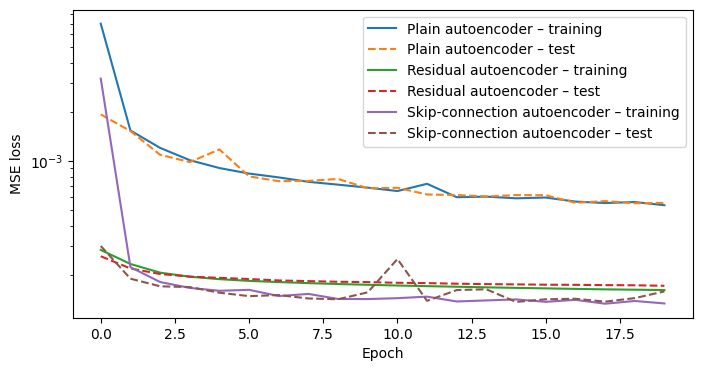

In [30]:
L = tf.keras.layers

def build_autoencoder(residual):
    inp = tf.keras.Input(shape=(None, None, len(BANDS)))
    # encoder
    x = L.Conv2D(64, 3, padding="same", activation="relu")(inp)
    x = L.MaxPooling2D(2)(x)
    x = L.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = L.MaxPooling2D(2)(x)                      # code: 1/4 of the original size
    # decoder
    x = L.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = L.UpSampling2D(2)(x)
    x = L.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = L.UpSampling2D(2)(x)
    out = L.Conv2D(len(BANDS), 3, padding="same")(x)
    if residual:
        out = L.Add()([inp, out])                 # learn only the missing details
    model = tf.keras.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model

def build_skip_autoencoder():
    # Encoder-decoder with skip connections, following the lecture tutorial
    # "Image Super Resolution using Autoencoders" (adapted to 4 bands).
    inp = tf.keras.Input(shape=(None, None, len(BANDS)))
    l1 = L.Conv2D(64, 3, padding="same", activation="relu")(inp)
    l2 = L.Conv2D(64, 3, padding="same", activation="relu")(l1)
    l3 = L.MaxPooling2D(2)(l2)
    l4 = L.Conv2D(128, 3, padding="same", activation="relu")(l3)
    l5 = L.Conv2D(128, 3, padding="same", activation="relu")(l4)
    l6 = L.MaxPooling2D(2)(l5)
    l7 = L.Conv2D(256, 3, padding="same", activation="relu")(l6)      # code
    l8 = L.UpSampling2D(2)(l7)
    l9 = L.Conv2D(128, 3, padding="same", activation="relu")(l8)
    l10 = L.Conv2D(128, 3, padding="same", activation="relu")(l9)
    l11 = L.Add()([l5, l10])                                           # skip connection
    l12 = L.UpSampling2D(2)(l11)
    l13 = L.Conv2D(64, 3, padding="same", activation="relu")(l12)
    l14 = L.Conv2D(64, 3, padding="same", activation="relu")(l13)
    l15 = L.Add()([l14, l2])                                           # skip connection
    out = L.Conv2D(len(BANDS), 3, padding="same")(l15)
    model = tf.keras.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model

MODEL_BUILDERS = {
    "Plain autoencoder": lambda: build_autoencoder(residual=False),
    "Residual autoencoder": lambda: build_autoencoder(residual=True),
    "Skip-connection autoencoder": build_skip_autoencoder,
}

models, histories = {}, {}
for name, builder in MODEL_BUILDERS.items():
    tf.keras.utils.set_random_seed(SEED)
    models[name] = builder()
    histories[name] = models[name].fit(lr_train, hr_train, epochs=EPOCHS, batch_size=32,
                                       validation_data=(lr_test, hr_test), verbose=0)
    print(f"{name}: trained, {models[name].count_params():,} parameters")

plt.figure(figsize=(8, 4))
for name, h in histories.items():
    plt.plot(h.history["loss"], label=f"{name} – training")
    plt.plot(h.history["val_loss"], "--", label=f"{name} – test")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.legend()
plt.show()

In [31]:
def psnr(a, b):
    # Peak signal-to-noise ratio per patch (data scaled to ~0-1), averaged over patches. Higher = better.
    mse = np.mean((a - b) ** 2, axis=(1, 2, 3))
    return np.mean(10 * np.log10(1.0 / mse))

def mse(a, b):
    return np.mean((a - b) ** 2)

preds = {name: m.predict(lr_test, verbose=0) for name, m in models.items()}
rows = [{"method": "Bicubic interpolation", "MSE": mse(lr_test, hr_test), "PSNR [dB]": psnr(lr_test, hr_test)}]
for name, pr in preds.items():
    rows.append({"method": name, "MSE": mse(pr, hr_test), "PSNR [dB]": psnr(pr, hr_test)})
sr_results = pd.DataFrame(rows).set_index("method")

sr_results.style.format({"MSE": "{:.6f}", "PSNR [dB]": "{:.2f}"})

,MSE,PSNR [dB]
method,,
Bicubic interpolation,0.000289,36.74
Plain autoencoder,0.000552,33.88
Residual autoencoder,0.000171,38.93
Skip-connection autoencoder,0.000158,39.05


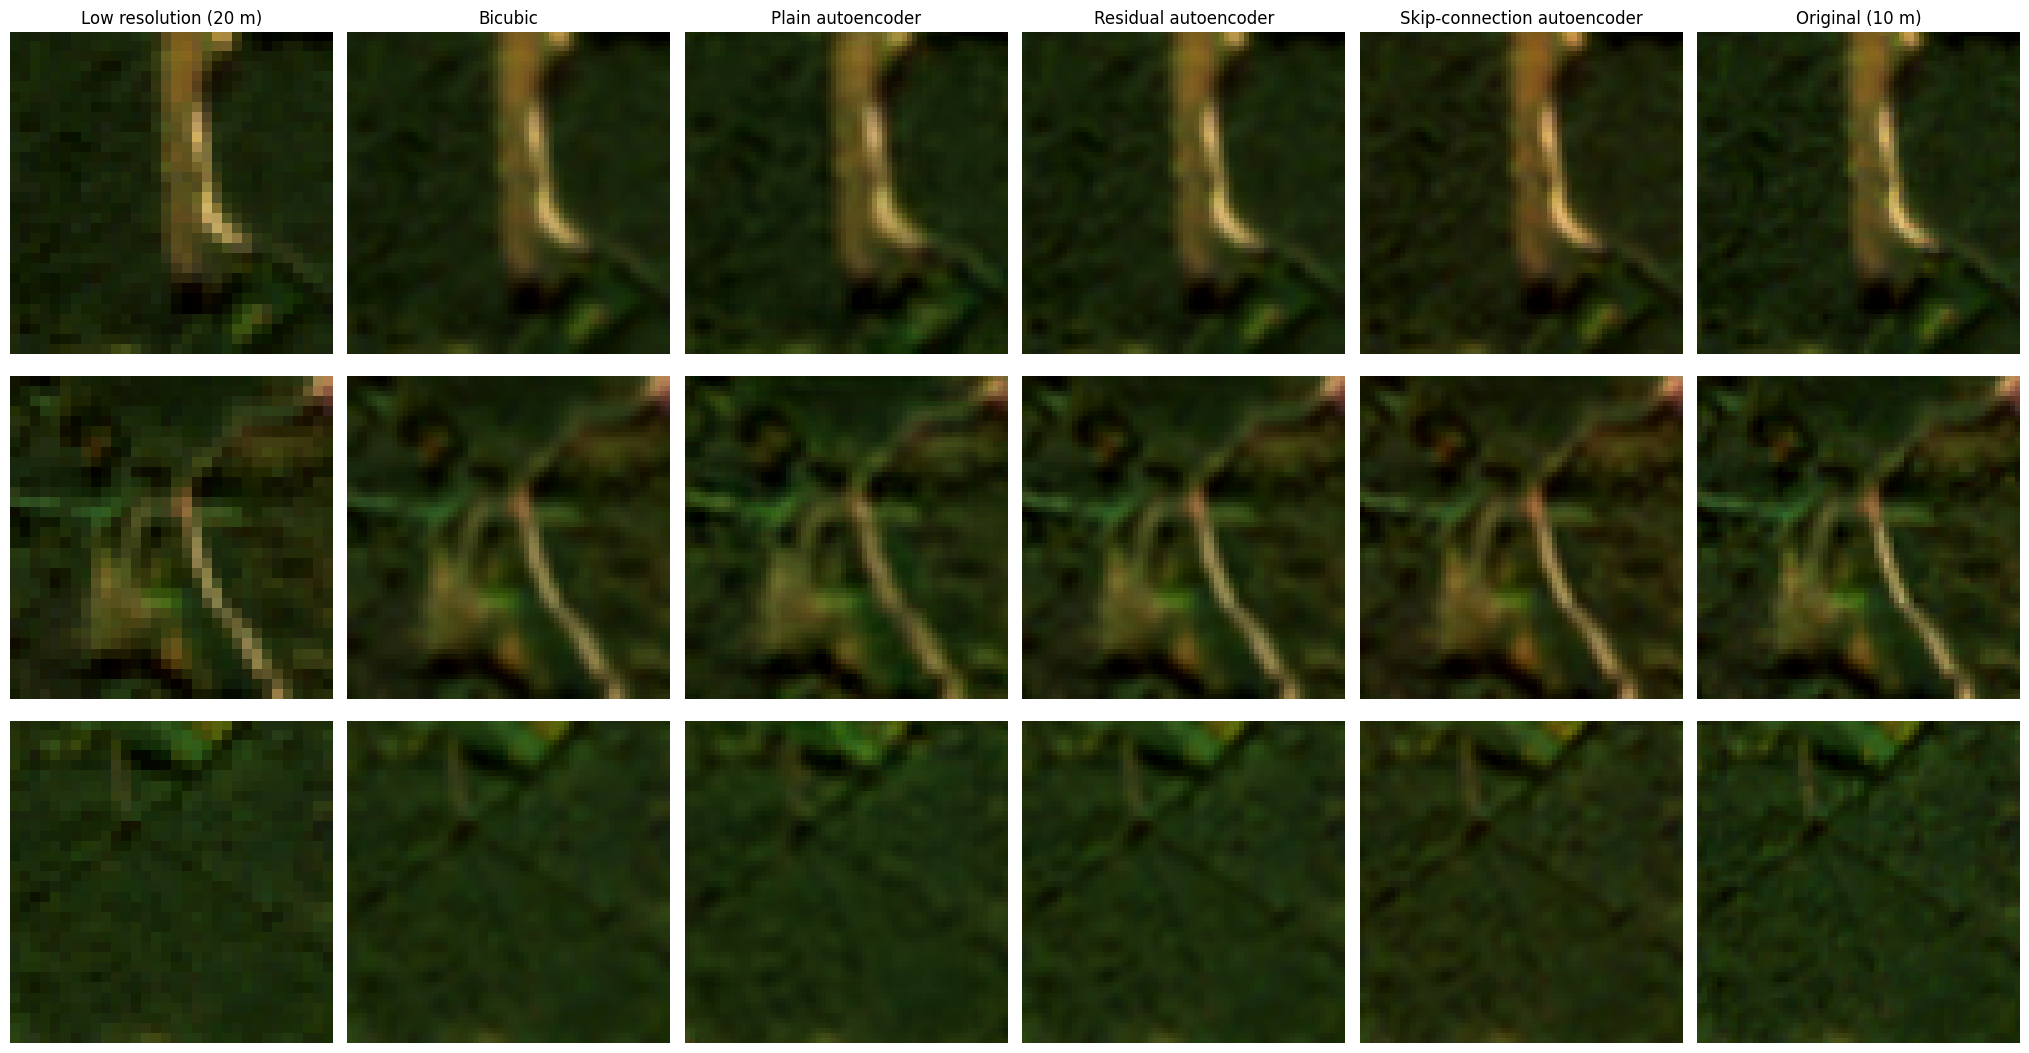

In [32]:
# visual comparison on test patches
idx = rng.choice(len(hr_test), 3, replace=False)
lo, hi = np.percentile(hr_test[..., [2, 1, 0]], [2, 98])
titles = ["Low resolution (20 m)", "Bicubic"] + list(preds) + ["Original (10 m)"]

fig, axes = plt.subplots(len(idx), len(titles), figsize=(3.4 * len(titles), 3.6 * len(idx)))
for row, i in enumerate(idx):
    lr_blocky = np.repeat(np.repeat(
        hr_test[i].reshape(SR_PATCH // 2, 2, SR_PATCH // 2, 2, -1).mean(axis=(1, 3)), 2, axis=0), 2, axis=1)
    images = [lr_blocky, lr_test[i]] + [pr[i] for pr in preds.values()] + [hr_test[i]]
    for col, (ax, im) in enumerate(zip(axes[row], images)):
        ax.imshow(to_rgb(im, lo, hi), interpolation='nearest')
        ax.set_title(titles[col] if row == 0 else "")
        ax.axis('off')
plt.tight_layout()
plt.show()

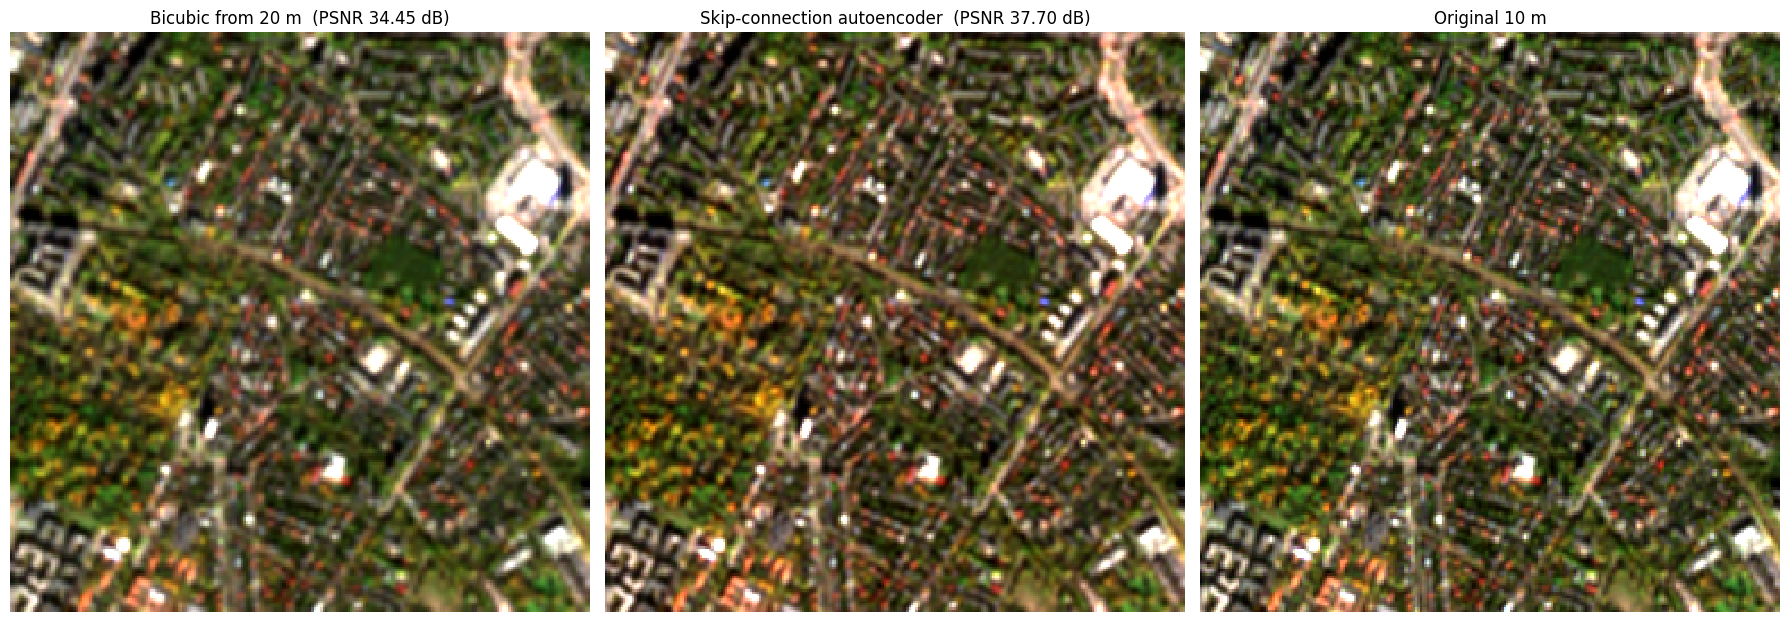

In [33]:
# applying the trained network to a larger test area (the network is fully convolutional)
img = locations["urban_krakow"] / SCALE
s = min(256, img.shape[0] // 4 * 4, img.shape[1] // 4 * 4)
r0, c0 = (img.shape[0] - s) // 2, (img.shape[1] - s) // 2
crop = img[None, r0:r0 + s, c0:c0 + s].astype(np.float32)
crop_lr = degrade(crop)
best = sr_results.drop("Bicubic interpolation")["PSNR [dB]"].idxmax()   # best network by test PSNR
crop_sr = models[best].predict(crop_lr, verbose=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, im, t in zip(axes, [crop_lr[0], crop_sr[0], crop[0]],
                     ["Bicubic from 20 m", best, "Original 10 m"]):
    ax.imshow(to_rgb(im, lo, hi), interpolation='nearest')
    ax.set_title(f"{t}  (PSNR {psnr(im[None], crop):.2f} dB)" if t != "Original 10 m" else t)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Does it enhance the resolution?

Yes, but only when the network is designed appropriately. Bicubic interpolation, used as the baseline, reconstructs the 10 m test patches from the simulated 20 m data with a PSNR of 36.74 dB. The results of the three autoencoders are very different:

- The plain autoencoder is worse than simple interpolation (33.88 dB, almost 3 dB below bicubic). All information has to pass through the bottleneck, which is four times smaller than the image, so fine details are lost in the compressed code. This illustrates the remark from the lecture that autoencoders are not good at compression. Its learning curve was also still decreasing after 20 epochs, so it had not fully converged.
- The residual autoencoder improves the result to 38.93 dB (+2.2 dB compared to bicubic, 41% lower MSE). Since its output is added to the input, it only needs to learn the missing details, and the information passed directly from the input does not have to go through the bottleneck. Its loss was already close to the bicubic level after the first epoch and converged quickly.
- The skip-connection autoencoder from the lecture tutorial gives the best result, 39.05 dB (+2.3 dB, 45% lower MSE), although it has over 20 times more parameters (1.1 million compared to 51 thousand) than the residual network, which achieves almost the same quality.

The improvement is visible in the images: roads and field boundaries are sharper and closer to the original than in the bicubic version, which looks blurry. Applied to a larger fragment of Kraków, the skip-connection network increased the PSNR from 34.45 dB to 37.70 dB (+3.3 dB), so the gain is even larger for urban areas, which contain many sharp edges. However, the networks do not recover everything: fine textures, such as the structure of forest canopies, remain smoother than in the original, since detail that was averaged out in the 20 m pixel cannot be fully restored. The training and test curves stay close to each other, so the networks did not overfit.

An important limitation is that the networks were trained and evaluated on a simulated problem (20 m -> 10 m, created by averaging 2 * 2 pixels). Applying them to real 10 m data to obtain 5 m images is possible, as the networks are fully convolutional, but the result cannot be verified, as no 5 m reference exists, and the real sensor blur differs from simple averaging.

### How can it work better?

The experiments already show two effective improvements: **residual learning** (predicting only the missing details) and **skip connections** between the encoder and the decoder, as in the U-Net. Both let fine details bypass the bottleneck, and the residual network achieved almost the same quality as the much larger skip-connection network. Further possible improvements:

- More and more diverse training data, e.g. more locations, land cover types and seasons, and longer training (the plain autoencoder had not converged after 20 epochs).
- A more realistic degradation model, simulating the real point spread function and noise of the sensor instead of simple 2 * 2 averaging, so that the network can be applied to real data.
- Real high-resolution targets, e.g. aerial orthophotos or commercial satellite images (such as PlanetScope) of the same area, instead of simulating the low resolution from the 10 m data.
- A different loss function. MSE favours smooth, average solutions; a loss based on structural similarity (SSIM) or perceptual features, or a GAN-based approach (e.g. SRGAN), produces sharper and more realistic textures. However, GANs may also generate details that do not exist in reality, which is a problem for scientific use of EO data.
- Using the 10 m bands to sharpen the 20 m bands of Sentinel-2 (e.g. red-edge and SWIR). This is a practical EO application, in which the high-resolution bands provide the missing spatial detail for the low-resolution ones.